# Mexican cartel–municipality network: descriptive EDA

Annual bipartite networks and descriptive statistics (1990–2010). Run cells from top to bottom. This notebook preserves the computations in `network_EDA.py`.

## 1. Load and validate the dataset

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

# Works when the notebook is in the project root (or data is alongside the notebook)
path = Path("data/CosciaRios2012_DataBase.csv")
if not path.exists():
    path = Path("CosciaRios2012_DataBase.csv")
df = pd.read_csv(path)
required = ["Code", "State", "Year"]
if not set(required).issubset(df.columns):
    raise ValueError(f"Missing required columns: {set(required) - set(df.columns)}")
cartels = [col for col in df.columns if col not in required]
if not cartels:
    raise ValueError("No cartel columns found")
if df.isna().any().any():
    raise ValueError("Dataset contains missing values")
if df.duplicated(["Code", "Year"]).any():
    raise ValueError("Duplicate municipality-year observations")
if not df[cartels].isin([0, 1]).all().all():
    raise ValueError("Cartel indicators must be binary (0 or 1)")
if (df.groupby("Code")["State"].nunique() > 1).any():
    raise ValueError("Some municipalities have inconsistent State values")

In [2]:
municipalities = df[["Code", "State"]].drop_duplicates("Code")
years_sorted = sorted(df["Year"].unique())
all_codes = municipalities["Code"]
expected = pd.MultiIndex.from_product(
    [all_codes, range(int(min(years_sorted)), int(max(years_sorted)) + 1)],
    names=["Code", "Year"],
)
missing_pairs = expected.difference(pd.MultiIndex.from_frame(df[["Code", "Year"]]))
print("shape:", df.shape)
print("years:", min(years_sorted), "-", max(years_sorted))
print("municipalities:", len(municipalities))
print("states:", df["State"].nunique())
print("missing values:", df.isna().sum().sum())
print("duplicate municipality-years:", df.duplicated(["Code", "Year"]).sum())
print("missing municipality-years:", len(missing_pairs))
if len(missing_pairs):
    print("examples of missing municipality-years:", list(missing_pairs[:10]))
print("cartel observations:\n", df[cartels].sum().sort_values(ascending=False))

shape: (51596, 13)
years: 1990 - 2010
municipalities: 2457
states: 32
missing values: 0
duplicate municipality-years: 0
missing municipality-years: 1
examples of missing municipality-years: [(32058, 2010)]
cartel observations:
 Zetas                   1587
Golfo                   1320
Sinaloa                  874
Familia                  644
Beltran_Leyva            588
Juarez                   421
Tijuana                  316
Otros                    171
Beltran_Leyva_Family     154
Sinaloa_Family           153
dtype: int64


## 2. Build annual bipartite networks

In [3]:
networks = {}
cartel_nodes = [("c", cartel) for cartel in cartels]
municipality_nodes = [("m", int(code)) for code in all_codes]
for year, rows in df.groupby("Year"):
    graph = nx.Graph(year=int(year))
    graph.add_nodes_from(
        (("m", int(row.Code)), {"bipartite": 0, "state": int(row.State)})
        for row in municipalities.itertuples(index=False)
    )
    graph.add_nodes_from((node, {"bipartite": 1}) for node in cartel_nodes)
    for row in rows.itertuples(index=False):
        for cartel in cartels:
            if getattr(row, cartel) == 1:
                graph.add_edge(("m", int(row.Code)), ("c", cartel))
    networks[int(year)] = graph

## 3. Network structure over time

In [4]:
summary = []
for year in years_sorted:
    graph = networks[year]
    degrees = np.array([graph.degree(node) for node in municipality_nodes])
    cartel_degrees = np.array([graph.degree(node) for node in cartel_nodes])
    active = degrees > 0
    active_nodes = [node for node, degree in graph.degree() if degree > 0]
    components = list(nx.connected_components(graph.subgraph(active_nodes))) if active_nodes else []
    largest_share = max(map(len, components)) / len(active_nodes) if components else 0
    summary.append({
        "year": year,
        "edges": graph.number_of_edges(),
        "active_municipalities": int(active.sum()),
        "active_cartels": int((cartel_degrees > 0).sum()),
        "isolated_municipalities": int((degrees == 0).sum()),
        "mean_degree_active": float(degrees[active].mean()) if active.any() else 0,
        "max_municipality_degree": int(degrees.max()),
        "mean_cartel_degree": float(cartel_degrees.mean()),
        "density": graph.number_of_edges() / (len(municipalities) * len(cartels)),
        "components_active": len(components),
        "largest_component_active": largest_share,
        "overlap_municipalities": int((degrees >= 2).sum()),
        "overlap_share_active": float((degrees >= 2).sum() / active.sum()) if active.any() else 0,
    })
summary = pd.DataFrame(summary).set_index("year").sort_index()
print("\nnetwork evolution:\n", summary.round(3))


network evolution:
       edges  active_municipalities  active_cartels  isolated_municipalities  \
year                                                                          
1990      0                      0               0                     2457   
1991      6                      6               2                     2451   
1992      6                      5               3                     2452   
1993     24                     22               5                     2435   
1994     31                     29               4                     2428   
1995     23                     20               4                     2437   
1996     36                     31               6                     2426   
1997     51                     48               6                     2409   
1998     49                     43               5                     2414   
1999     31                     28               5                     2429   
2000     60                    

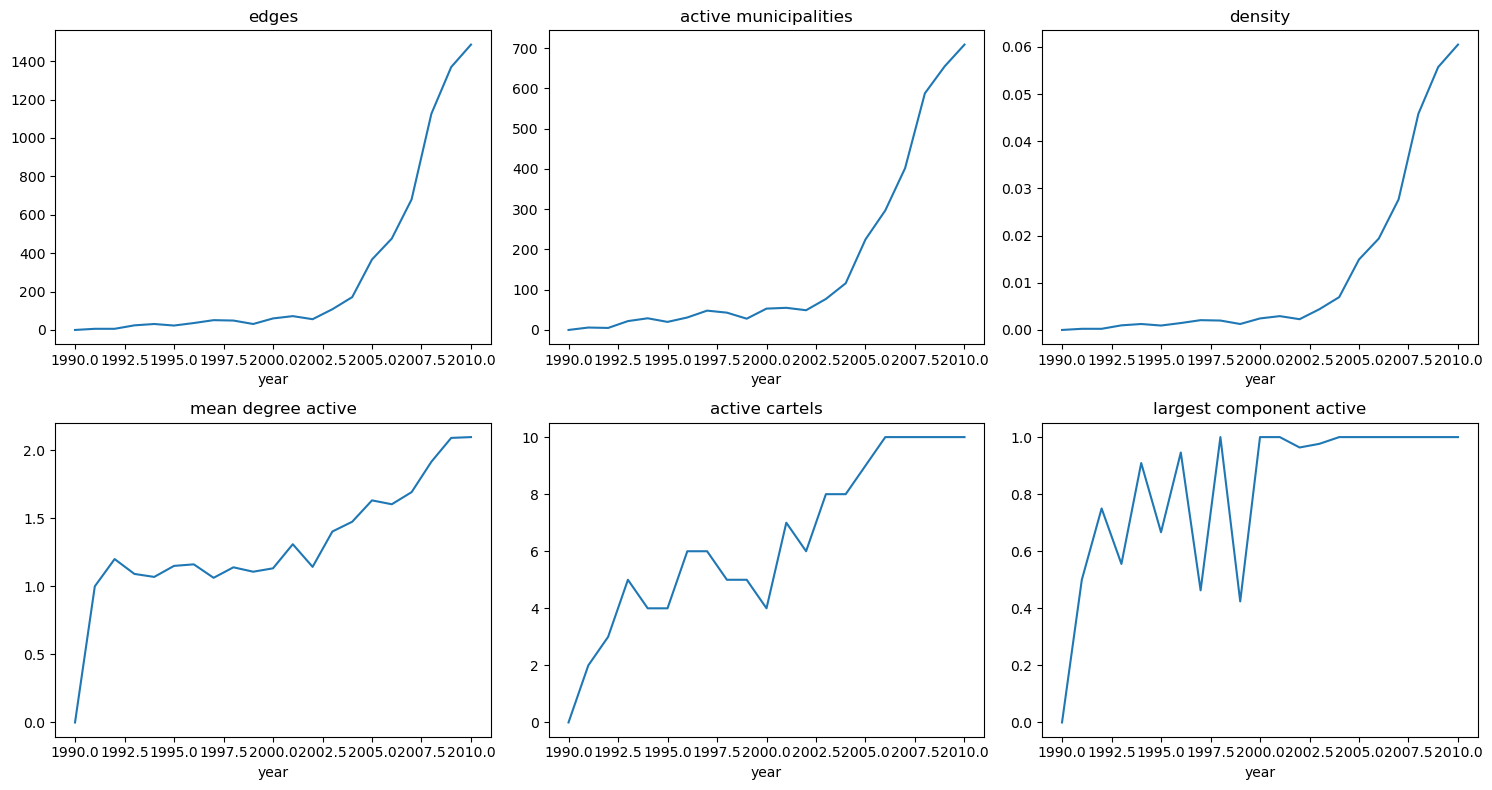

In [5]:
columns = ["edges", "active_municipalities", "density", "mean_degree_active", "active_cartels", "largest_component_active"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, columns):
    summary[column].plot(ax=ax, title=column.replace("_", " "))
    ax.set_xlabel("year")
plt.tight_layout()
plt.show()

## 4. Municipality degree distributions

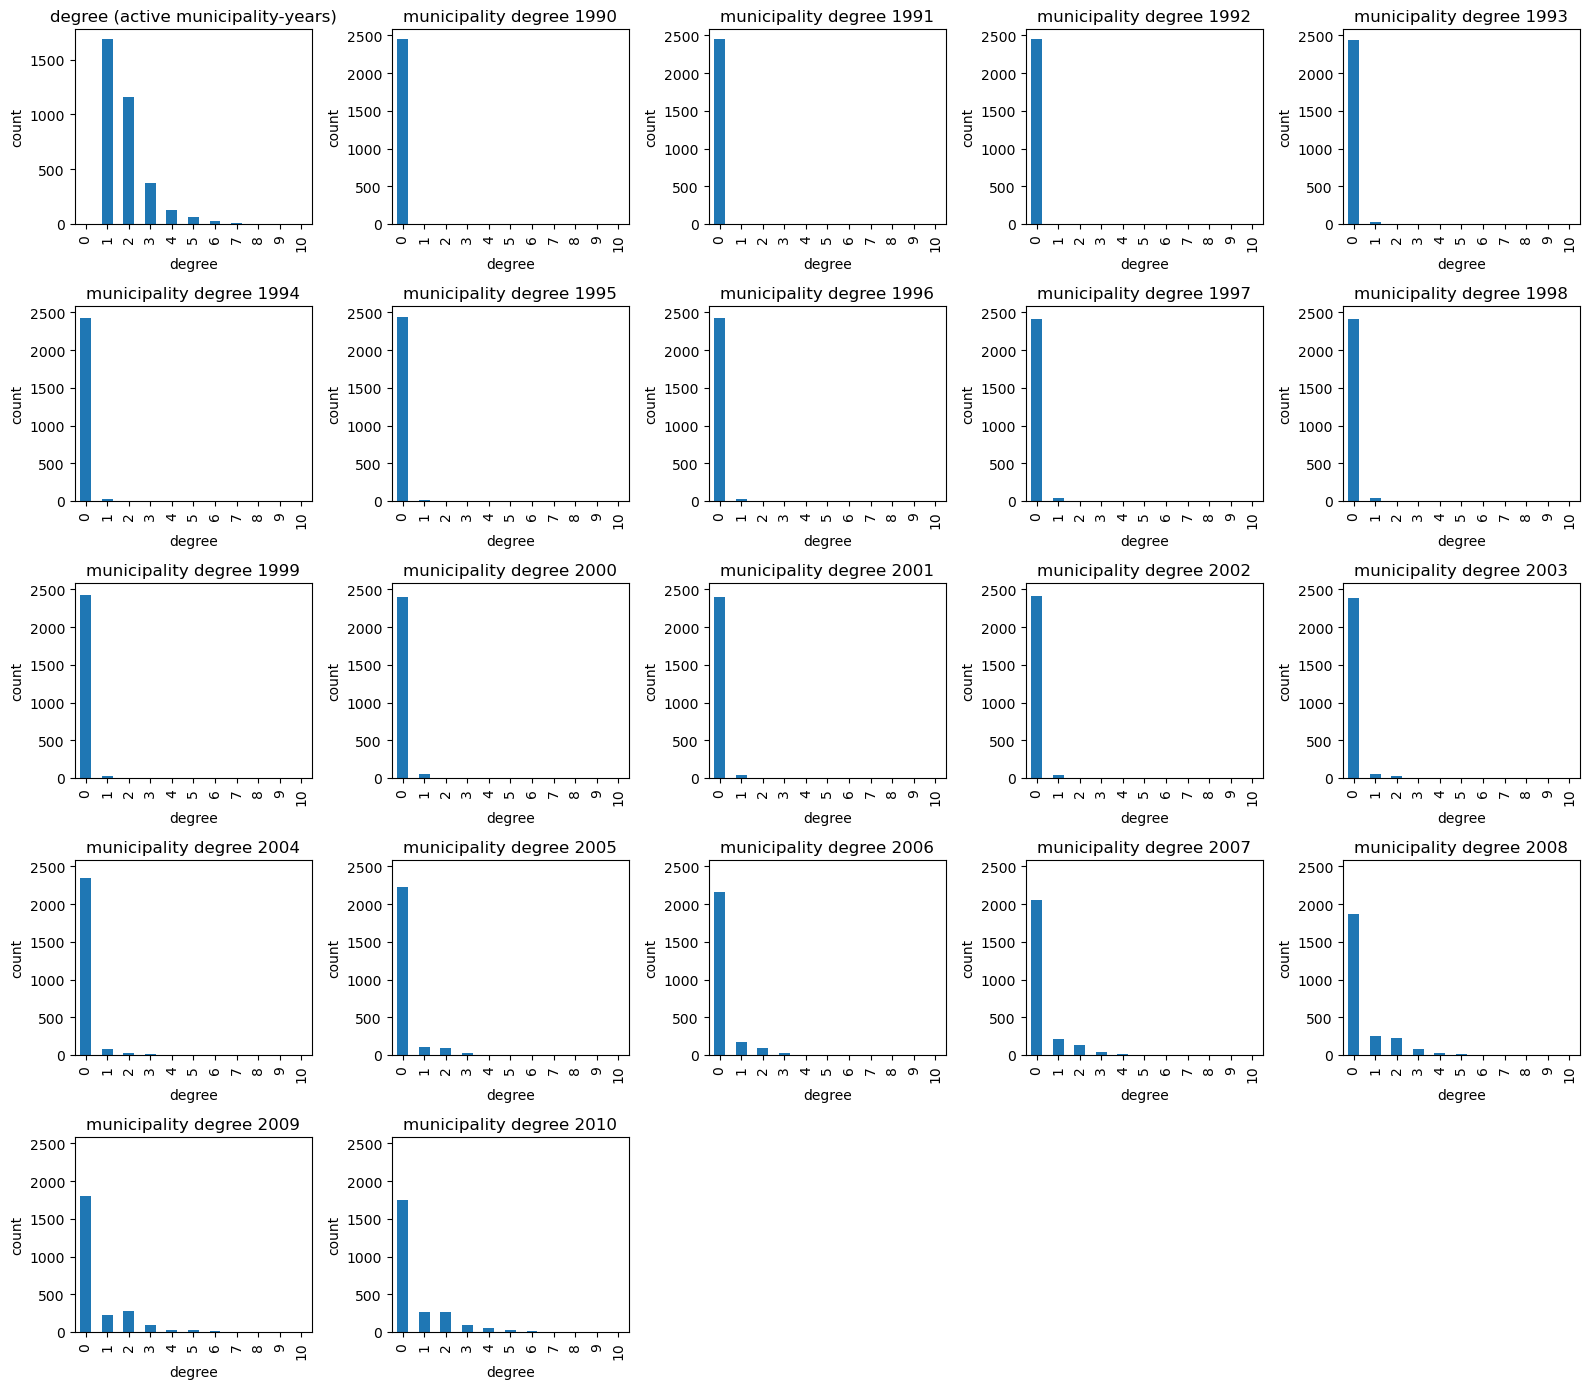

In [6]:
municipality_degree = df.assign(degree=df[cartels].sum(axis=1))
cols = 5
rows = (len(years_sorted) + 1 + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 2.8), squeeze=False)
degree_range = range(len(cartels) + 1)
aggregate_counts = municipality_degree.loc[municipality_degree["degree"] > 0, "degree"].value_counts().reindex(degree_range, fill_value=0)
aggregate_counts.plot.bar(ax=axes.flat[0])
axes.flat[0].set(title="degree (active municipality-years)", xlabel="degree", ylabel="count")
annual_counts = []
for year in years_sorted:
    yearly_degrees = municipality_degree.loc[municipality_degree["Year"] == year, "degree"]
    annual_counts.append(yearly_degrees.value_counts().reindex(degree_range, fill_value=0))
max_count = max((counts.max() for counts in annual_counts), default=0)
for i, (year, counts) in enumerate(zip(years_sorted, annual_counts), start=1):
    counts.plot.bar(ax=axes.flat[i])
    axes.flat[i].set(title=f"municipality degree {year}", xlabel="degree", ylabel="count", ylim=(0, max_count * 1.05 + 1))
for j in range(len(years_sorted) + 1, rows * cols):
    axes.flat[j].axis("off")
# Missing municipality-year observations are not interpreted as degree zero.
plt.tight_layout()
plt.show()

## 5. Cartel activity

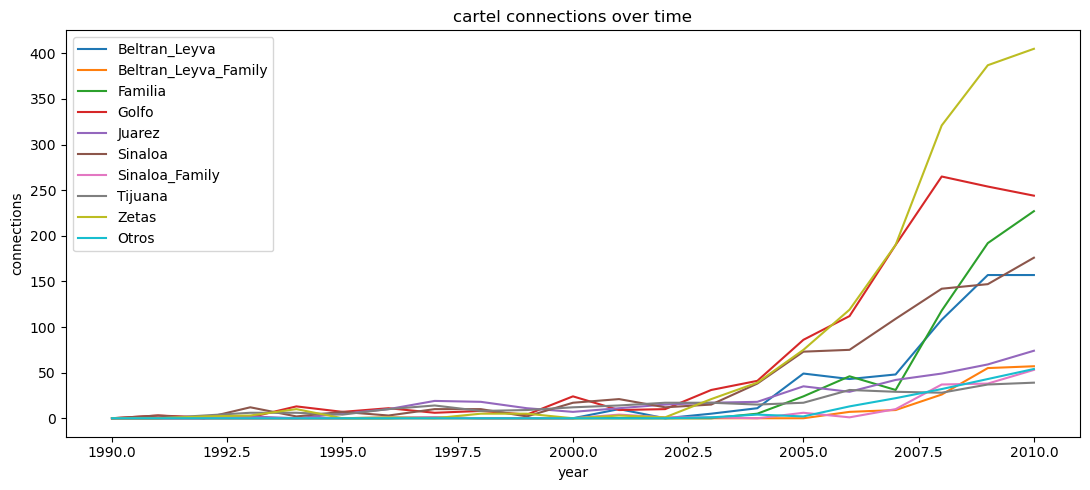

In [7]:
cartel_year_counts = df.groupby("Year")[cartels].sum().sort_index()
cartel_year_counts.plot(figsize=(11, 5), title="cartel connections over time")
plt.xlabel("year")
plt.ylabel("connections")
plt.tight_layout()
plt.show()

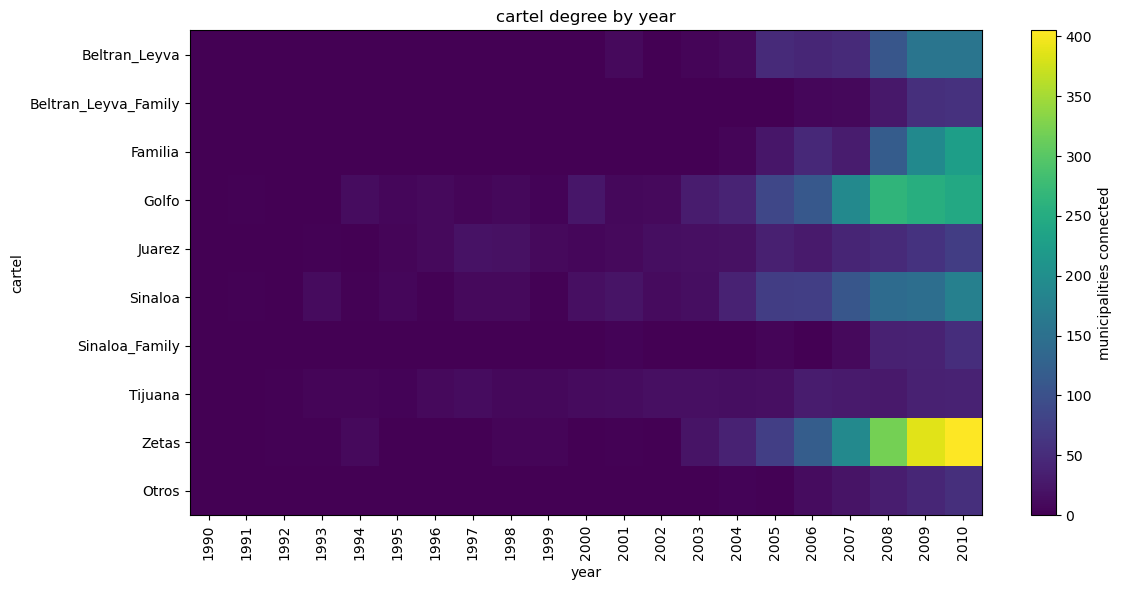

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(cartel_year_counts.T, aspect="auto")
ax.set_xticks(range(len(cartel_year_counts)), cartel_year_counts.index, rotation=90)
ax.set_yticks(range(len(cartels)), cartels)
ax.set(title="cartel degree by year", xlabel="year", ylabel="cartel")
fig.colorbar(image, ax=ax, label="municipalities connected")
plt.tight_layout()
plt.show()

In [9]:
top_municipalities = municipality_degree.groupby("Code")["degree"].max().sort_values(ascending=False).head(10)
print("\ntop municipalities by maximum yearly degree:\n", top_municipalities)


top municipalities by maximum yearly degree:
 Code
8037     9
16054    8
28014    7
16046    7
10005    7
15106    7
17007    7
17018    7
19031    7
25006    7
Name: degree, dtype: int64


## 6. Annual cartel projections

Each weighted edge represents the number of shared municipalities. Node positions and edge-width scaling are held constant across years.

In [10]:
projections = {year: nx.bipartite.weighted_projected_graph(networks[year], cartel_nodes) for year in years_sorted}
aggregate_projection = nx.Graph()
aggregate_projection.add_nodes_from(cartel_nodes)
for projection in projections.values():
    for u, v, data in projection.edges(data=True):
        if aggregate_projection.has_edge(u, v):
            aggregate_projection[u][v]["weight"] += data["weight"]
        else:
            aggregate_projection.add_edge(u, v, weight=data["weight"])
positions = nx.spring_layout(aggregate_projection, weight="weight", seed=42)
max_weight = max((data["weight"] for projection in projections.values() for _, _, data in projection.edges(data=True)), default=1)

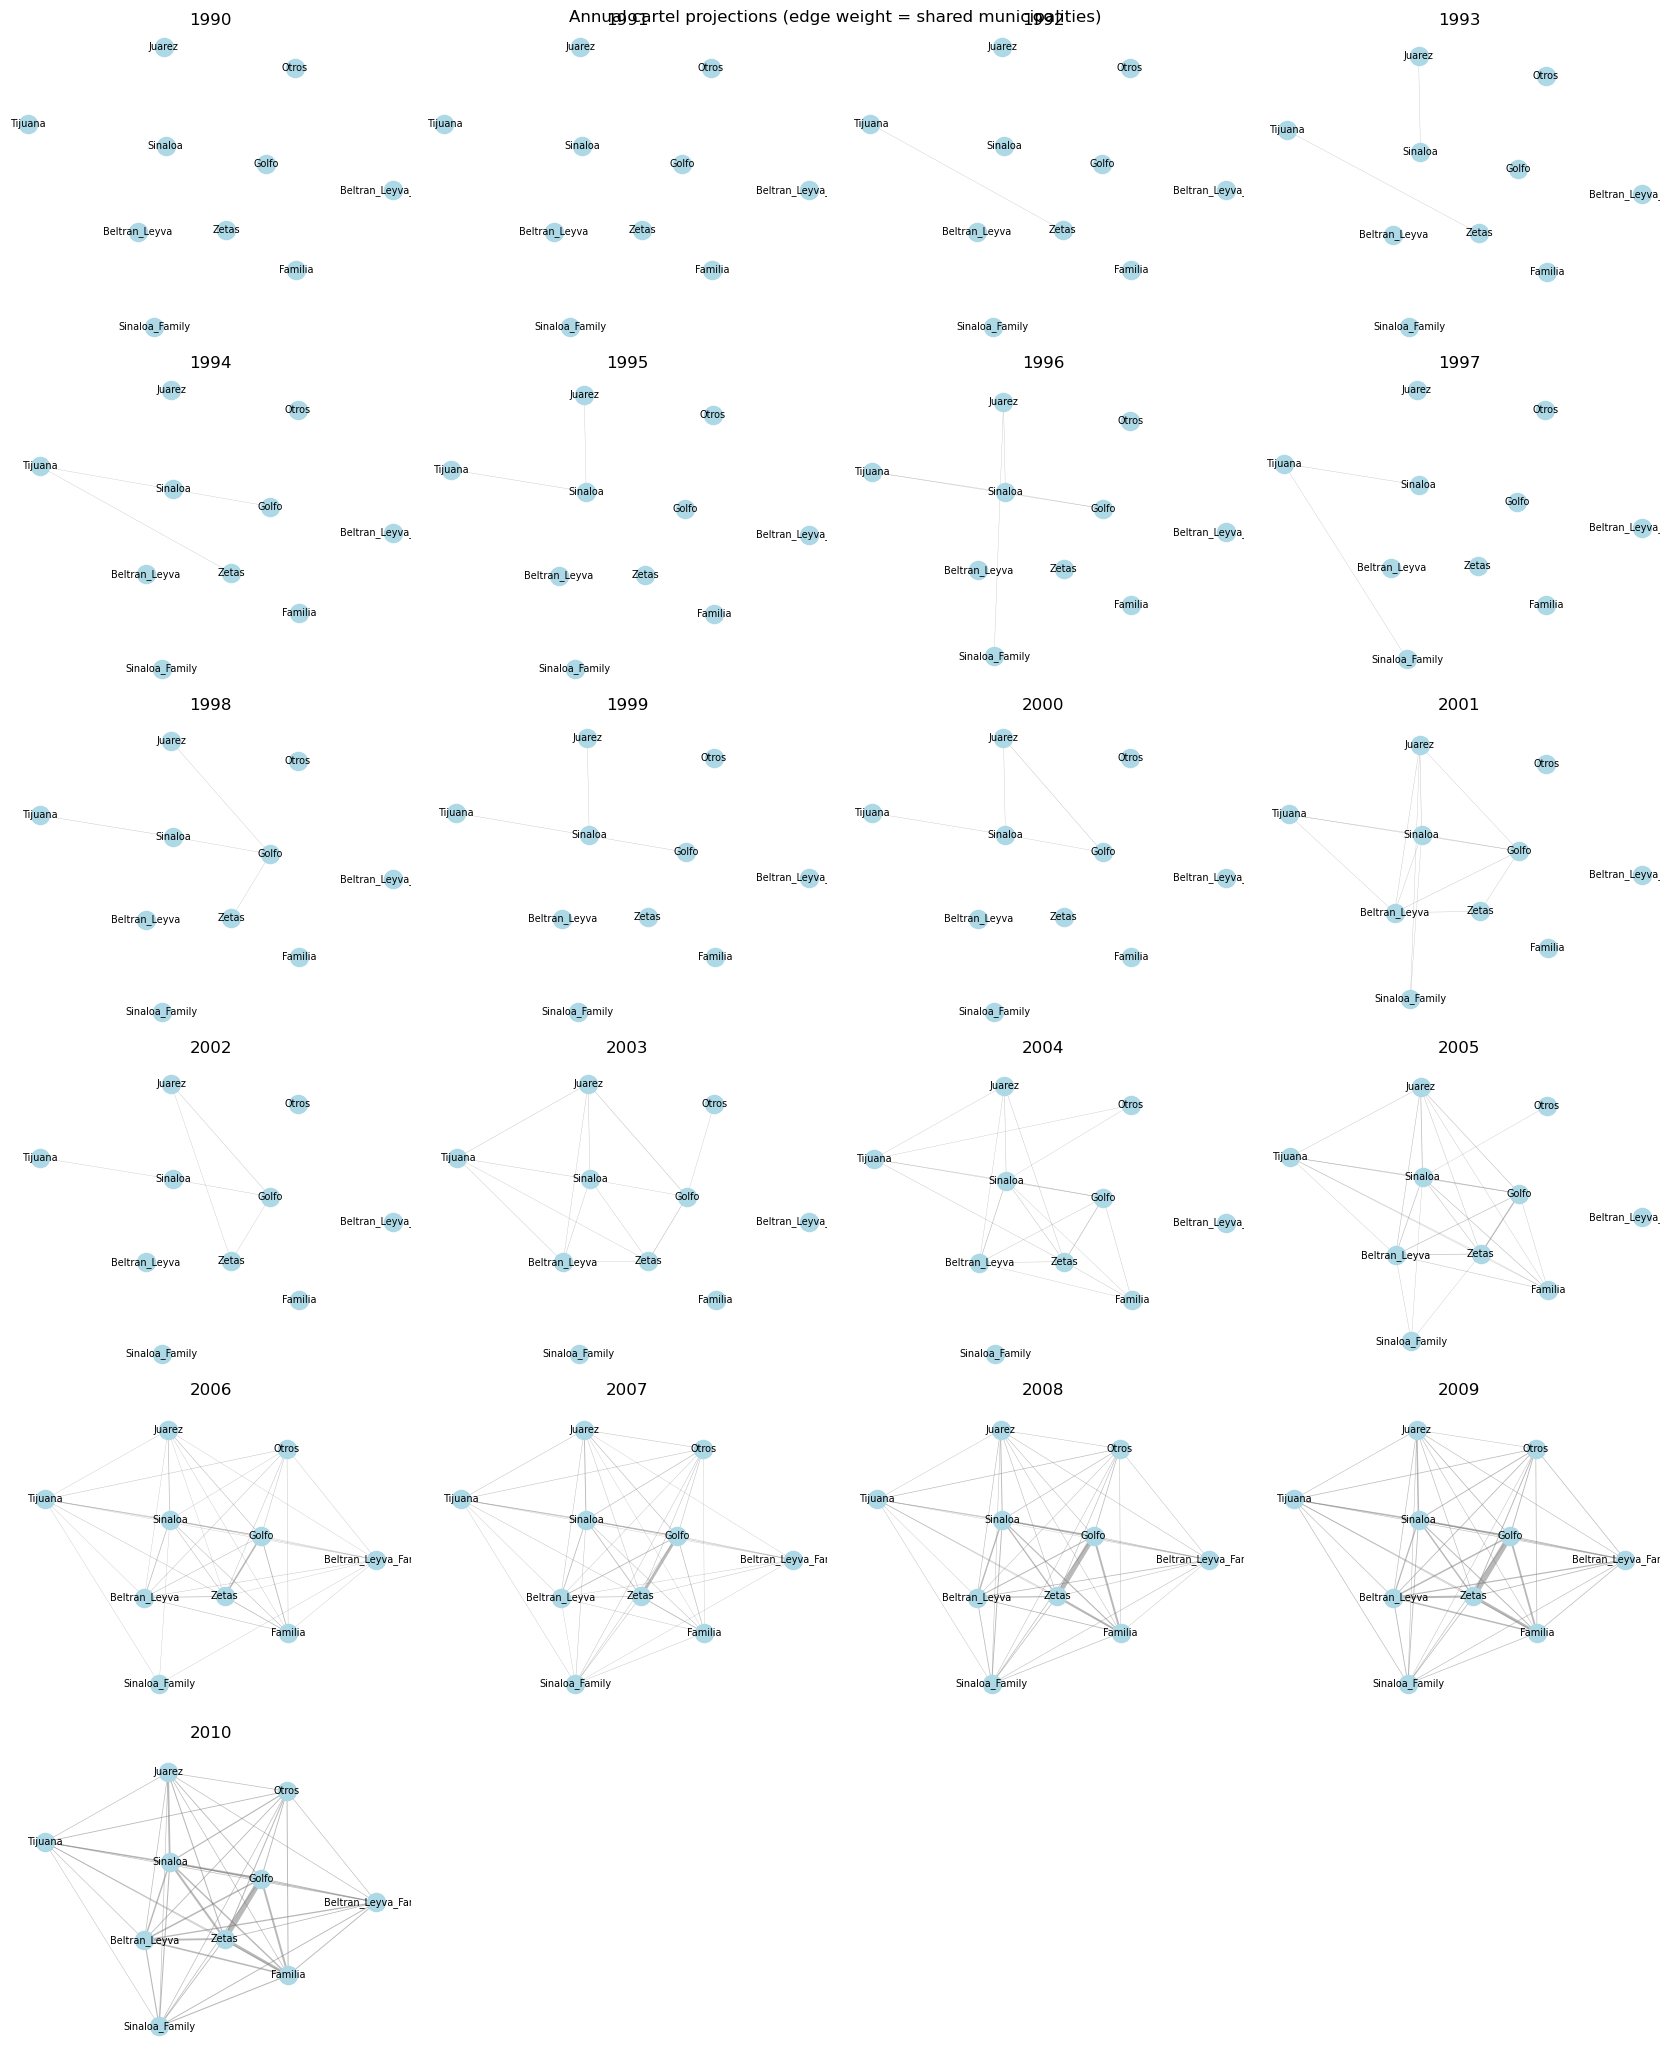

In [11]:
cols = 4
rows = (len(years_sorted) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.2, rows * 3.5), squeeze=False)
for i, year in enumerate(years_sorted):
    ax = axes.flat[i]
    projection = projections[year]
    nx.draw_networkx_nodes(projection, positions, node_size=170, node_color="lightblue", ax=ax)
    nx.draw_networkx_labels(projection, positions, labels={node: node[1] for node in cartel_nodes}, font_size=7, ax=ax)
    widths = [0.2 + 3.8 * data["weight"] / max_weight for _, _, data in projection.edges(data=True)]
    nx.draw_networkx_edges(projection, positions, width=widths, edge_color="gray", alpha=0.55, ax=ax)
    ax.set_title(str(year))
    ax.axis("off")
for j in range(len(years_sorted), rows * cols):
    axes.flat[j].axis("off")
fig.suptitle("Annual cartel projections (edge weight = shared municipalities)")
plt.tight_layout()
plt.show()

## 7. Municipality activity composition

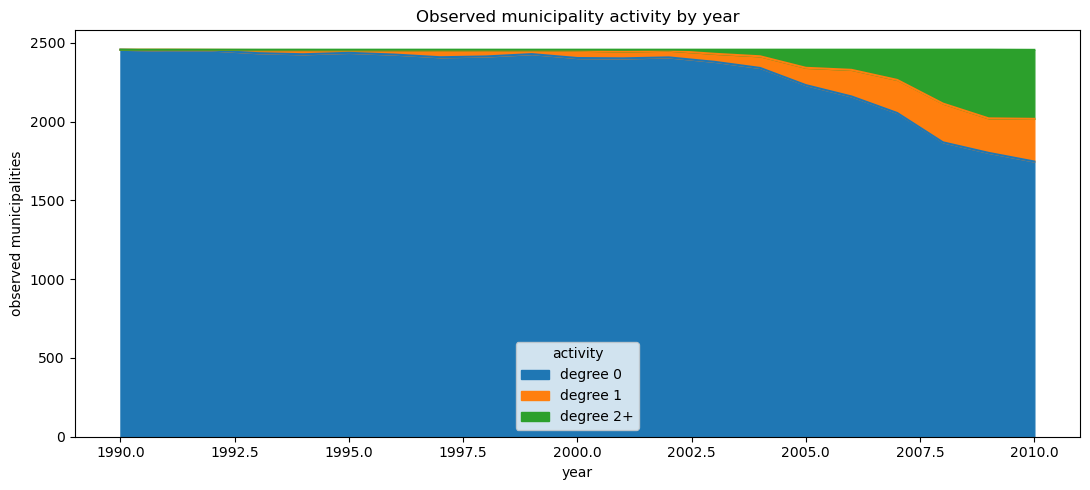

In [12]:
activity = municipality_degree.assign(
    activity=np.select(
        [municipality_degree["degree"] == 0, municipality_degree["degree"] == 1],
        ["degree 0", "degree 1"],
        default="degree 2+",
    )
)
activity_counts = pd.crosstab(activity["Year"], activity["activity"]).reindex(
    index=years_sorted, columns=["degree 0", "degree 1", "degree 2+"], fill_value=0
)
activity_counts.plot.area(figsize=(11, 5), title="Observed municipality activity by year")
plt.xlabel("year")
plt.ylabel("observed municipalities")
plt.tight_layout()
plt.show()

## 8. Cartel overlap and co-occurrence

Co-occurrence is descriptive; it does not by itself imply cooperation or rivalry.


cartel co-occurrence (municipality-years):
                       Beltran_Leyva  Beltran_Leyva_Family  Familia  Golfo  \
Beltran_Leyva                     0                    96      127    159   
Beltran_Leyva_Family             96                     0       43     65   
Familia                         127                    43        0    215   
Golfo                           159                    65      215      0   
Juarez                           55                    34       35     89   
Sinaloa                         177                    71      126    190   
Sinaloa_Family                   70                    46       56     46   
Tijuana                          32                    26       24     65   
Zetas                           197                    50      285    729   
Otros                            55                    34       52     72   

                      Juarez  Sinaloa  Sinaloa_Family  Tijuana  Zetas  Otros  
Beltran_Leyva             55

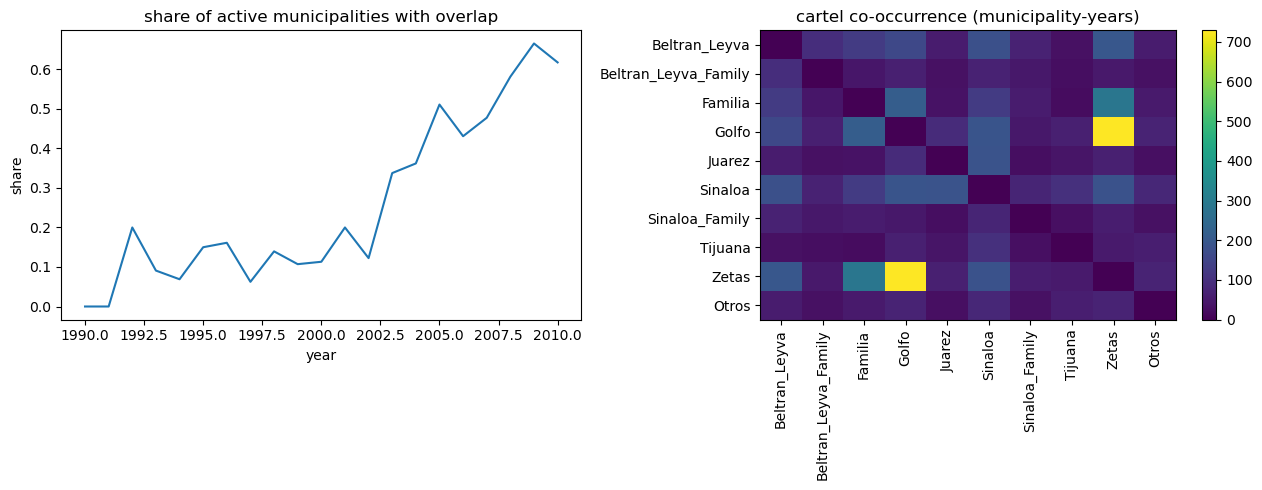

In [13]:
cooccurrence = df[cartels].T.dot(df[cartels])
np.fill_diagonal(cooccurrence.values, 0)
print("\ncartel co-occurrence (municipality-years):\n", cooccurrence)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
summary["overlap_share_active"].plot(ax=axes[0])
axes[0].set(title="share of active municipalities with overlap", xlabel="year", ylabel="share")
image = axes[1].imshow(cooccurrence, aspect="auto")
axes[1].set_xticks(range(len(cartels)), cartels, rotation=90)
axes[1].set_yticks(range(len(cartels)), cartels)
axes[1].set_title("cartel co-occurrence (municipality-years)")
fig.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

## 9. Connection changes between consecutive years

In [14]:
changes = []
previous_edges = None
seen_edges = set()
for year in years_sorted:
    graph = networks[year]
    # Use a consistent (municipality, cartel) order for undirected edges.
    edges = {(u, v) if u[0] == "m" else (v, u) for u, v in graph.edges()}
    if previous_edges is not None:
        new = edges - previous_edges
        lost = previous_edges - edges
        persistent = edges & previous_edges
        first_time = new - seen_edges
        returning = new & seen_edges
        occupied = sum(previous_graph.degree(municipality) > 0 for municipality, _ in new)
        # Formation denominator uses all possible edges in the fixed node universe.
        possible_absent = len(municipalities) * len(cartels) - len(previous_edges)
        changes.append({
            "year": year,
            "new": len(new),
            "lost": len(lost),
            "persistent": len(persistent),
            "first_time": len(first_time),
            "returning": len(returning),
            "new_in_occupied": occupied,
            "new_in_unoccupied": len(new) - occupied,
            "persistence_rate": len(persistent) / len(previous_edges) if previous_edges else np.nan,
            "formation_rate": len(new) / possible_absent if possible_absent else np.nan,
            "disappearance_rate": len(lost) / len(previous_edges) if previous_edges else np.nan,
        })
    seen_edges.update(edges)
    previous_edges = edges
    previous_graph = graph
changes = pd.DataFrame(changes).set_index("year")
print("\nconnection changes:\n", changes.round(3))


connection changes:
       new  lost  persistent  first_time  returning  new_in_occupied  \
year                                                                  
1991    6     0           0           6          0                0   
1992    6     6           0           6          0                0   
1993   21     3           3          20          1                0   
1994   25    18           6          22          3                5   
1995   15    23           8          11          4                5   
1996   28    15           8          24          4                7   
1997   42    27           9          37          5                9   
1998   37    39          12          30          7               14   
1999   24    42           7          15          9                6   
2000   53    24           7          27         26               14   
2001   59    47          13          43         16               25   
2002   42    58          14          19         23     

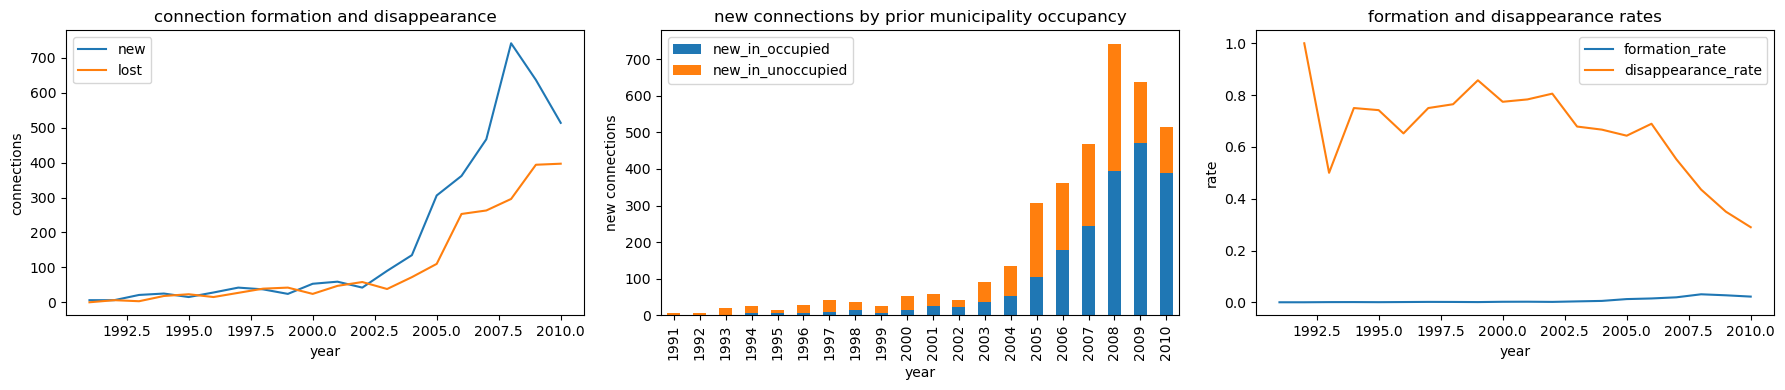

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
changes[["new", "lost"]].plot(ax=axes[0])
axes[0].set(title="connection formation and disappearance", xlabel="year", ylabel="connections")
changes[["new_in_occupied", "new_in_unoccupied"]].plot.bar(stacked=True, ax=axes[1])
axes[1].set(title="new connections by prior municipality occupancy", xlabel="year", ylabel="new connections")
changes[["formation_rate", "disappearance_rate"]].plot(ax=axes[2])
axes[2].set(title="formation and disappearance rates", xlabel="year", ylabel="rate")
plt.tight_layout()
plt.show()